![Solved Problem](assets/solvedproblem1.png)

![Solved Problem](assets/solvedproblem2.png)

![Solved Problem](assets/solvedproblem3.png)

In [81]:
import pygad

In [82]:
def amount_of_change(solution):
    num_quarters = int(solution[0])
    num_dimes = int(solution[1])
    num_nickels = int(solution[2])
    num_pennies = int(solution[3])
    return(num_quarters * 0.25 + num_dimes * 0.10 + num_nickels * 0.05 + num_pennies * 0.01)

In [83]:
def get_total_number_of_coins(solution):
    return int(sum(solution))

In [ ]:
def evaluate_raw_fitness(solution):
    change = amount_of_change(solution)
    total_coins = get_total_number_of_coins(solution)

    change_difference = abs(TARGET_AMOUNT - change)
    # factorul de scalare: am pus 100000 in loc de 300 ca sa sa evit cazurile de
    # genul [7 1 0 4] (12 coins pt 1.84 dar cu fitness 12) vs [7 1 0 0] (8 coins pt 1.85 dar gitness 8.03)
    fitness = 100000  * (change_difference ** 2) + total_coins #de intrebat daca e ok asa sau tb total_coins if total_coins > 1 else 0
    return fitness

In [85]:
def fitness_func(ga_instance, solution, solution_idx):
    return -evaluate_raw_fitness(solution)

In [86]:
def display_individual(solution):
    raw_fitness = evaluate_raw_fitness(solution)
    coins_str = " ".join(str(int(gene)) for gene in solution)
    total_change = amount_of_change(solution)
    print(f"Solution: {coins_str} | Total Change: ${total_change:.2f} | Raw Fitness: {raw_fitness:.2f}")

In [87]:
def on_generation(ga_instance):
    best_solution, _, _ = ga_instance.best_solution()
    gen = ga_instance.generations_completed
    print(f"Gen {gen:3d} | ", end="")
    display_individual(best_solution)

In [ ]:
TARGET_AMOUNT = 1.84
NUM_EVOLUTIONS = 300 # default era 100
POPULATION_SIZE = 150 #default era 80

Gen   1 | Solution: 0 12 6 36 | Total Change: $1.86 | Raw Fitness: 94.00
Gen   2 | Solution: 4 3 9 11 | Total Change: $1.86 | Raw Fitness: 67.00
Gen   3 | Solution: 2 6 8 33 | Total Change: $1.83 | Raw Fitness: 59.00
Gen   4 | Solution: 0 9 15 20 | Total Change: $1.85 | Raw Fitness: 54.00
Gen   5 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen   6 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen   7 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen   8 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen   9 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen  10 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen  11 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen  12 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen  13 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitness: 38.00
Gen  14 | Solution: 1 2 26 9 | Total Change: $1.84 | Raw Fitne

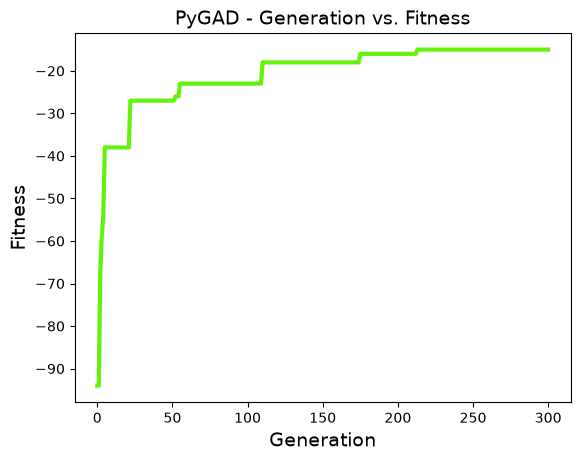

In [ ]:
def main():
    gene_space = [
        range(0, 21),
        range(0, 31),
        range(0, 51),
        range(0, 81)
    ]

    ga_instance = pygad.GA(
        num_generations=NUM_EVOLUTIONS,
        num_parents_mating=POPULATION_SIZE // 2,
        fitness_func=fitness_func,
        sol_per_pop=POPULATION_SIZE,
        num_genes=4,
        gene_space=gene_space,
        gene_type=int,
        keep_elitism=1,  # Equivalent to conf.setPreservFittestIndividual(true)
        on_generation=on_generation,
    )

    ### O INSTANTA MAI EXPLICATA:

    # ga_instance = pygad.GA(
    #     num_generations=NUM_EVALUATIONS,
    #     num_parents_mating=POPULATION_SIZE // 2,
    #     fitness_func=fitness_func,
    #     sol_per_pop=POPULATION_SIZE,
    #     num_genes=4,
    #     gene_space=gene_space,
    #     gene_type=int,
    #     parent_selection_type = "sss", #sss inseamna steady state selection, adica selecteaza parintii in functie de fitness-ul lor
    #     keep_elitism = 1,
    #     crossover_type = "single_point", #single_point inseamna ca se va face crossover-ul la un singur punct, adica se va alege un punct random si se vor schimba genele de la acel punct incolo intre cei doi parinti
    #     crossover_probability = 0.9,
    #     mutation_type = "random", #random inseamna ca se va alege un gene random si se va schimba cu un alt gene random din gene_space
    #     mutation_probability = 1/10,
    #     on_generation=on_generation
    # )

    ga_instance.run()
    ga_instance.plot_fitness()

if __name__ == "__main__":
    main()

dupa ce am schimbat factorul de scaling ca sa fie mai important un rest exact, am ajuns la solutiile care dau rest fix
Gen  60 | Solution: 2 6 12 14 | Total Change: $1.84 | Raw Fitness: 34.00
Gen  61 | Solution: 2 6 12 14 | Total Change: $1.84 | Raw Fitness: 34.00
Gen  62 | Solution: 2 6 12 14 | Total Change: $1.84 | Raw Fitness: 34.00
Gen  63 | Solution: 2 6 12 14 | Total Change: $1.84 | Raw Fitness: 34.00
Gen  64 | Solution: 2 6 12 14 | Total Change: $1.84 | Raw Fitness: 34.00
Gen  65 | Solution: 2 6 12 14 | Total Change: $1.84 | Raw Fitness: 34.00
Gen  66 | Solution: 2 6 12 14 | Total Change: $1.84 | Raw Fitness: 34.00
Gen  67 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  68 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  69 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  70 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  71 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  72 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  73 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  74 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  75 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  76 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  77 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  78 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  79 | Solution: 1 9 12 9 | Total Change: $1.84 | Raw Fitness: 31.00
Gen  80 | Solution: 3 4 12 9 | Total Change: $1.84 | Raw Fitness: 28.00
intre ele s-a facut departajarea prin numarul minim de monede

[2 6 12 14] -> fitness 34
[1 9 12 9] -> fitness 31
[3 4 12 9] -> fitness 28

Deci, s-a favorizat [3 4 12 9] pt ca foloseste cel mai mic nr de monede, are fitness = 100000 x 0 + (3+4+12+9) = 28 (cel mai mic din cele 3)

Cu o populatie de 150 si 300 de evolutii, solutia cea mai buna a fost gasita pentru o rulare la generatia 137 (dar nu a fost gasita la fiecare rulare, cum e si normal)

Gen 136 | Solution: 4 6 4 4 | Total Change: $1.84 | Raw Fitness: 18.00
Gen 137 | Solution: 7 0 1 4 | Total Change: $1.84 | Raw Fitness: 12.00
